In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

First 5 records:
   speed  dist
0      4     2
1      4    10
2      7     4
3      7    22
4      8    16


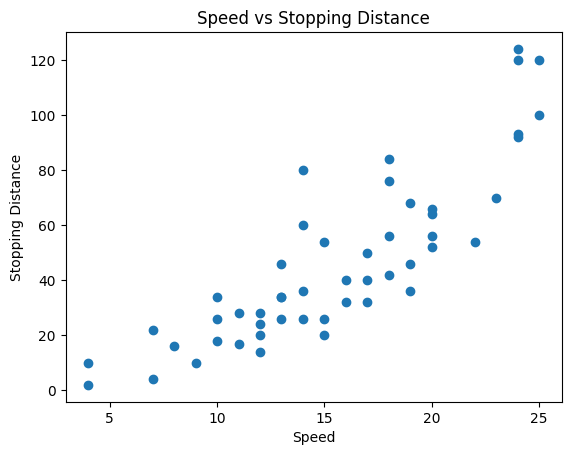

In [2]:
df = pd.read_csv("cars.csv")

print("First 5 records:")
print(df.head())

plt.scatter(df['speed'], df['dist'])
plt.xlabel("Speed")
plt.ylabel("Stopping Distance")
plt.title("Speed vs Stopping Distance")
plt.show()

In [3]:
X = df[['speed']]
y = df['dist']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 40
Testing data: 10


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [6]:
intercept = model.intercept_
slope = model.coef_[0]

print("\nRegression Equation:")
print("dist =", intercept, "+", slope, "* speed")


Regression Equation:
dist = -25.933755819438417 + 4.726040320761292 * speed


In [7]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Distance': y_test.values,
    'Predicted Distance': y_pred
})
print(result)

   Actual Distance  Predicted Distance
0               24           30.778728
1               56           68.587051
2               50           54.408930
3               93           87.491212
4               34           35.504768
5              100           92.217252
6               32           49.682889
7               54           44.956849
8               56           59.134970
9               26           40.230809


In [8]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mse)

print("MSE:", mse)
print("MAE:", mae)
print("R2 Score:", r2)
print("RMSE:", rmse)

MSE: 92.38130012434165
MAE: 8.266283147726577
R2 Score: 0.8511539513021161
RMSE: 9.611519137178142


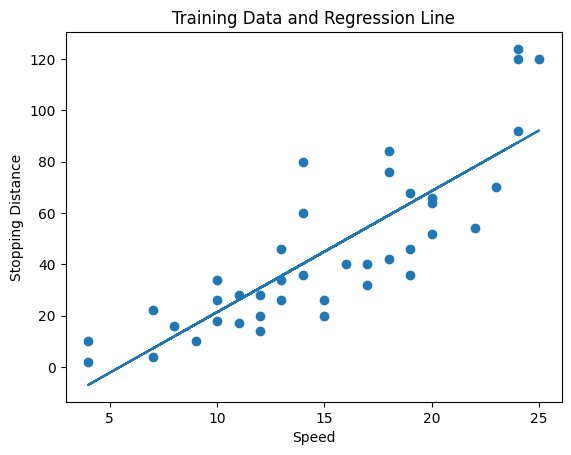

In [9]:
plt.scatter(X_train, y_train)
plt.plot(X_train, model.predict(X_train))
plt.xlabel("Speed")
plt.ylabel("Stopping Distance")
plt.title("Training Data and Regression Line")
plt.show()

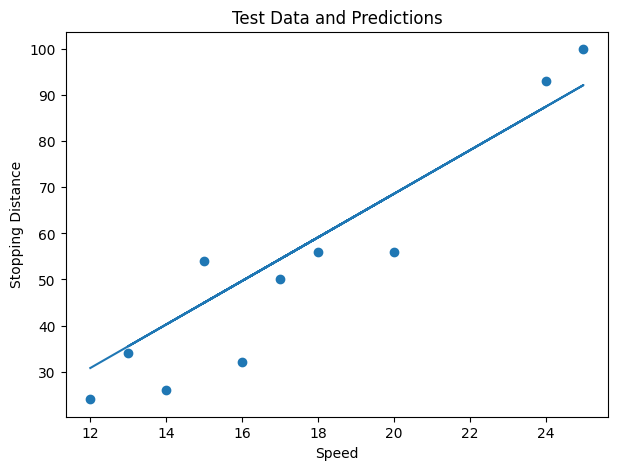

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred)
plt.xlabel("Speed")
plt.ylabel("Stopping Distance")
plt.title("Test Data and Predictions")
plt.show()

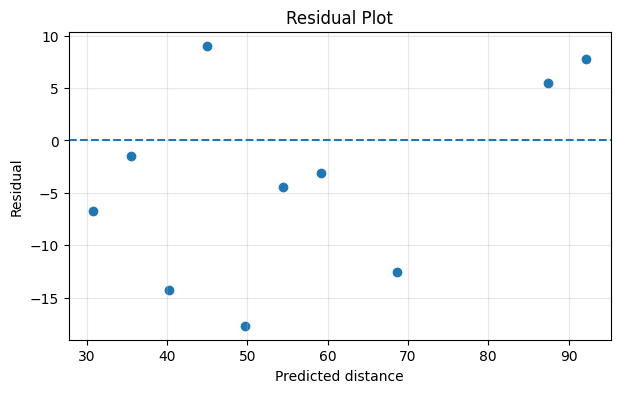

In [11]:
residuals = y_test - y_pred
plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted distance")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.show()